# Prototipo de Sistema de Gestión del Conocimiento – Spotify
**Clasificación automática de documentos y búsqueda semántica**

Avance del proyecto de la materia *Sistemas y tecnologías de administración del conocimiento*.

Para ejecutarlo, corre las celdas en orden con ▶ (o `Shift + Enter`). Cada paso muestra su resultado debajo. No hace falta instalar ni subir nada, porque los documentos de prueba ya vienen dentro del cuaderno.

## Paso 1. Importar las librerías
Se usan `scikit-learn` (aprendizaje automático), `numpy` y `pandas` (tablas). Colab ya las trae instaladas.

In [1]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 80)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Paso 2. Cargar los documentos
Usamos 40 documentos **simulados** del área de desarrollo de software de Spotify, 8 de cada una de las 5 categorías. Cada uno tiene título, texto y categoría. Los mismos documentos, junto con los 6 nuevos del paso 6, están en el archivo `documentos_prueba.csv` del repositorio.

In [2]:
DOCUMENTOS = [
    {"id": "DT01", "titulo": "Guía de despliegue del servicio de pagos", "texto": "Guía de despliegue del servicio de pagos. Esta guía explica cómo desplegar una nueva versión del servicio de pagos. El squad debe crear la rama de lanzamiento, ejecutar las pruebas automáticas y publicar la imagen del contenedor en el registro interno. Después se actualiza el manifiesto de Kubernetes y se monitorean las métricas de latencia durante treinta minutos. Si la tasa de errores supera el uno por ciento se ejecuta el procedimiento de reversión.", "categoria": "documentacion_tecnica"},
    {"id": "DT02", "titulo": "Arquitectura del servicio de autenticación", "texto": "Arquitectura del servicio de autenticación. El servicio de autenticación valida las credenciales de los usuarios y emite tokens de acceso con una vigencia de una hora. Se comunica con el servicio de cuentas mediante una API interna y guarda las sesiones en una base de datos distribuida. Este documento describe los componentes, los diagramas de arquitectura, los puertos utilizados y las dependencias de cada microservicio.", "categoria": "documentacion_tecnica"},
    {"id": "DT03", "titulo": "Configuración del entorno local de desarrollo", "texto": "Configuración del entorno local de desarrollo. Para trabajar en el código del reproductor web cada ingeniero debe instalar las herramientas de compilación, clonar el repositorio y configurar las variables de entorno. La guía incluye los comandos para levantar los servicios simulados con contenedores, ejecutar las pruebas unitarias y conectar el depurador. También explica cómo registrar el componente en el catálogo de Backstage.", "categoria": "documentacion_tecnica"},
    {"id": "DT04", "titulo": "Especificación de la API de playlists", "texto": "Especificación de la API de playlists. La API de playlists permite crear, editar y ordenar listas de reproducción. Cada endpoint recibe peticiones en formato JSON y responde con códigos de estado estándar. Esta especificación documenta los parámetros, los límites de peticiones por minuto, los mensajes de error y los ejemplos de uso para que otros squads integren la funcionalidad en sus servicios.", "categoria": "documentacion_tecnica"},
    {"id": "DT05", "titulo": "Manual de monitoreo y alertas de la plataforma", "texto": "Manual de monitoreo y alertas de la plataforma. El manual describe los tableros de monitoreo de la plataforma de streaming y las alertas configuradas para cada servicio. Se indican los umbrales de latencia, consumo de memoria y errores del servidor que activan una alerta automática. También explica cómo el ingeniero de guardia consulta los registros, revisa las trazas distribuidas y escala la alerta al squad responsable.", "categoria": "documentacion_tecnica"},
    {"id": "DT06", "titulo": "Modelo de datos del sistema de recomendaciones", "texto": "Modelo de datos del sistema de recomendaciones. Este documento técnico describe las tablas y los esquemas que usa el sistema de recomendaciones. Se detallan los campos de historial de reproducción, las señales de saltos y guardados, y la forma en que los datos se procesan en lotes cada noche para entrenar los modelos. Incluye diagramas del flujo de datos y la versión de cada esquema.", "categoria": "documentacion_tecnica"},
    {"id": "DT07", "titulo": "Procedimiento de migración de base de datos", "texto": "Procedimiento de migración de base de datos. Para migrar la base de datos del servicio de cuentas a la nueva versión del motor, el squad debe respaldar los datos, ejecutar los scripts de migración en el entorno de pruebas y validar la integridad de los registros. La guía describe cada comando, el tiempo estimado de la ventana de mantenimiento y los pasos para revertir la migración si falla.", "categoria": "documentacion_tecnica"},
    {"id": "DT08", "titulo": "Estándares de código y revisión entre pares", "texto": "Estándares de código y revisión entre pares. Los estándares de código definen cómo nombrar variables, estructurar los módulos y escribir pruebas unitarias en Java y Python. Cada cambio debe pasar por una revisión entre pares antes de integrarse a la rama principal. El documento incluye la lista de verificación para revisores, las reglas del analizador estático y la cobertura mínima de pruebas requerida.", "categoria": "documentacion_tecnica"},
    {"id": "EX01", "titulo": "Resultado de prueba A/B: recordatorio de renovación", "texto": "Resultado de prueba A/B: recordatorio de renovación. Se comparó el mensaje actual de renovación de Premium contra una versión con recordatorio tres días antes del cobro. La muestra fue de cincuenta mil usuarios divididos al azar en dos grupos. La versión B redujo las cancelaciones en cuatro por ciento con significancia estadística. Se recomienda lanzar la versión B a todos los mercados.", "categoria": "experimento_ab"},
    {"id": "EX02", "titulo": "Experimento: nuevo diseño de la pantalla de inicio", "texto": "Experimento: nuevo diseño de la pantalla de inicio. El experimento probó un diseño de la pantalla de inicio con accesos directos más grandes a las playlists recientes. El grupo de prueba aumentó el tiempo de escucha diario en dos por ciento, pero la métrica de descubrimiento de música nueva bajó ligeramente. La decisión fue iterar el diseño antes de lanzarlo.", "categoria": "experimento_ab"},
    {"id": "EX03", "titulo": "Prueba A/B: duración del periodo de prueba gratuita", "texto": "Prueba A/B: duración del periodo de prueba gratuita. Se evaluó si ofrecer tres meses de prueba gratuita en lugar de uno aumenta la conversión a Premium. El grupo B tuvo más registros, pero una tasa de conversión final similar al grupo de control. El análisis de costo concluyó que la variante no es rentable y se mantiene el periodo de un mes.", "categoria": "experimento_ab"},
    {"id": "EX04", "titulo": "Experimento con recomendaciones de podcasts", "texto": "Experimento con recomendaciones de podcasts. Se probó mostrar recomendaciones de podcasts dentro de las playlists de música. La hipótesis era que aumentaría el consumo de podcasts sin afectar la escucha de música. El grupo de prueba incrementó las reproducciones de podcasts en seis por ciento y la escucha de música no cambió. El experimento se considera exitoso.", "categoria": "experimento_ab"},
    {"id": "EX05", "titulo": "Resultado de prueba A/B: orden de resultados de búsqueda", "texto": "Resultado de prueba A/B: orden de resultados de búsqueda. La prueba comparó el orden actual de resultados de búsqueda contra un modelo que prioriza artistas seguidos por el usuario. La tasa de clics en el primer resultado subió de cuarenta y dos a cuarenta y ocho por ciento. Con un nivel de confianza del noventa y cinco por ciento se recomienda adoptar el nuevo modelo.", "categoria": "experimento_ab"},
    {"id": "EX06", "titulo": "Experimento: precio del plan familiar", "texto": "Experimento: precio del plan familiar. En tres mercados se probó un precio menor para el plan familiar. La métrica principal fue el número de nuevas suscripciones familiares y la secundaria el ingreso por usuario. Las suscripciones aumentaron nueve por ciento, pero el ingreso total bajó. El equipo de producto decidió no cambiar el precio y probar otros beneficios.", "categoria": "experimento_ab"},
    {"id": "EX07", "titulo": "Prueba A/B: notificación de lanzamientos de artistas", "texto": "Prueba A/B: notificación de lanzamientos de artistas. Se comparó enviar la notificación de un nuevo lanzamiento el mismo día contra enviarla al día siguiente. El grupo que recibió la notificación el mismo día tuvo una tasa de apertura mayor y más reproducciones en la primera semana. La diferencia fue estadísticamente significativa y se adoptó el envío inmediato.", "categoria": "experimento_ab"},
    {"id": "EX08", "titulo": "Experimento con la función de letras en pantalla", "texto": "Experimento con la función de letras en pantalla. Se midió el efecto de mostrar las letras de las canciones de forma automática en la pantalla del reproductor. El grupo de prueba aumentó la interacción con la pantalla y el número de canciones compartidas. No se observaron efectos negativos en la retención. Se recomienda activar la función por defecto en móviles.", "categoria": "experimento_ab"},
    {"id": "IU01", "titulo": "Estudio: por qué los usuarios cancelan Premium", "texto": "Estudio: por qué los usuarios cancelan Premium. Se realizaron veinte entrevistas a usuarios que cancelaron su suscripción Premium. Los motivos principales fueron el precio, el uso de otra plataforma y la falta de tiempo para escuchar música. Varios participantes dijeron que volverían con un plan más flexible. Se recomienda explorar planes con menor precio para estudiantes y usuarios ocasionales.", "categoria": "investigacion_usuarios"},
    {"id": "IU02", "titulo": "Investigación sobre hábitos de escucha de podcasts", "texto": "Investigación sobre hábitos de escucha de podcasts. La encuesta a dos mil usuarios mostró que la mayoría escucha podcasts mientras viaja o hace ejercicio. Los usuarios valoran poder continuar el episodio donde lo dejaron y recibir recomendaciones de temas nuevos. Los hallazgos indican que la experiencia de descubrimiento de podcasts aún es confusa para los usuarios nuevos.", "categoria": "investigacion_usuarios"},
    {"id": "IU03", "titulo": "Pruebas de usabilidad de la biblioteca", "texto": "Pruebas de usabilidad de la biblioteca. Ocho participantes realizaron tareas en la sección de biblioteca de la aplicación. La mayoría tuvo dificultad para encontrar los álbumes descargados y para filtrar por artista. Los participantes describieron la navegación como poco clara. Se proponen mejoras en los filtros y en las etiquetas de cada sección.", "categoria": "investigacion_usuarios"},
    {"id": "IU04", "titulo": "Entrevistas con artistas emergentes", "texto": "Entrevistas con artistas emergentes. Se entrevistó a quince artistas independientes sobre su experiencia con la plataforma. Valoran las estadísticas de oyentes, pero consideran difícil entender cómo se incluyen sus canciones en las playlists editoriales. Los artistas pidieron más información sobre su audiencia por ciudad y recomendaciones para promocionar sus lanzamientos.", "categoria": "investigacion_usuarios"},
    {"id": "IU05", "titulo": "Estudio de accesibilidad con usuarios con discapacidad visual", "texto": "Estudio de accesibilidad con usuarios con discapacidad visual. Se observó a diez usuarios con discapacidad visual mientras usaban la aplicación con lector de pantalla. Algunos botones no tenían etiquetas descriptivas y los participantes se perdían al cambiar de pestaña. El estudio recomienda revisar las etiquetas, el orden de navegación y el contraste de colores en toda la aplicación.", "categoria": "investigacion_usuarios"},
    {"id": "IU06", "titulo": "Investigación sobre el uso en América Latina", "texto": "Investigación sobre el uso en América Latina. La investigación combinó encuestas y diarios de uso de usuarios en México, Brasil y Colombia. Muchos usuarios escuchan con datos móviles limitados y descargan música con wifi. Las playlists de géneros regionales tienen gran aceptación. Se recomienda mejorar el modo de ahorro de datos y fortalecer el contenido editorial local.", "categoria": "investigacion_usuarios"},
    {"id": "IU07", "titulo": "Encuesta de satisfacción con las recomendaciones", "texto": "Encuesta de satisfacción con las recomendaciones. La encuesta preguntó a los usuarios qué tan útiles les parecen sus recomendaciones semanales. El setenta por ciento las calificó como buenas, pero muchos dijeron que se repiten los mismos artistas. Los participantes quieren más variedad y la opción de indicar qué no les gusta para mejorar sus recomendaciones.", "categoria": "investigacion_usuarios"},
    {"id": "IU08", "titulo": "Estudio etnográfico: la música en el trabajo", "texto": "Estudio etnográfico: la música en el trabajo. El equipo de investigación acompañó a doce personas durante su jornada laboral para entender cómo usan la música para concentrarse. Prefieren playlists sin letra y sesiones largas sin interrupciones. Varios participantes usan temporizadores de enfoque. Los hallazgos inspiraron la idea de una función de concentración dentro de la aplicación.", "categoria": "investigacion_usuarios"},
    {"id": "PO01", "titulo": "Política de privacidad y protección de datos de usuarios", "texto": "Política de privacidad y protección de datos de usuarios. Esta política establece cómo los colaboradores deben tratar los datos personales de los usuarios. Solo se permite acceder a la información necesaria para cada tarea y siempre de forma anonimizada cuando sea posible. Cualquier uso de datos para análisis debe cumplir con el reglamento europeo de protección de datos y con las leyes locales de cada país.", "categoria": "politica_interna"},
    {"id": "PO02", "titulo": "Política de seguridad de la información", "texto": "Política de seguridad de la información. Todos los colaboradores deben usar autenticación de dos factores, cifrar sus equipos y reportar cualquier incidente de seguridad en menos de veinticuatro horas. Está prohibido compartir contraseñas o almacenar credenciales en el código fuente. El incumplimiento de esta política puede generar sanciones disciplinarias según el reglamento interno.", "categoria": "politica_interna"},
    {"id": "PO03", "titulo": "Lineamientos de uso responsable de inteligencia artificial", "texto": "Lineamientos de uso responsable de inteligencia artificial. Los modelos de inteligencia artificial que afecten a usuarios o artistas deben pasar por una revisión de sesgos y de transparencia antes de lanzarse. Los equipos deben documentar los datos de entrenamiento, el propósito del modelo y los mecanismos de supervisión humana. Esta política aplica a recomendaciones, moderación de contenido y generación de audio.", "categoria": "politica_interna"},
    {"id": "PO04", "titulo": "Política de retención y eliminación de registros", "texto": "Política de retención y eliminación de registros. Los registros de actividad de los usuarios se conservan solo durante el tiempo necesario para operar el servicio y cumplir con las obligaciones legales. Esta política define los plazos de retención por tipo de dato, los responsables de autorizar la eliminación y el procedimiento para atender solicitudes de borrado de los usuarios.", "categoria": "politica_interna"},
    {"id": "PO05", "titulo": "Código de conducta para colaboradores", "texto": "Código de conducta para colaboradores. El código de conducta describe los valores de la empresa y el comportamiento esperado de todos los colaboradores. Incluye reglas sobre respeto, diversidad, conflictos de interés, uso de recursos de la empresa y canales para denunciar conductas indebidas de forma confidencial. Su cumplimiento es obligatorio y se revisa cada año.", "categoria": "politica_interna"},
    {"id": "PO06", "titulo": "Política de licencias y derechos de autor del catálogo", "texto": "Política de licencias y derechos de autor del catálogo. Esta política establece que solo se puede publicar contenido con licencia vigente en cada país. El equipo legal valida los contratos con sellos discográficos y editoras, y define las reglas de regalías. Cualquier contenido que reciba una reclamación de derechos de autor debe retirarse de forma temporal mientras se revisa el caso.", "categoria": "politica_interna"},
    {"id": "PO07", "titulo": "Política de acceso a sistemas internos", "texto": "Política de acceso a sistemas internos. El acceso a los sistemas internos se otorga según el principio de mínimo privilegio. Cada solicitud debe ser aprobada por el líder del squad y revisada cada trimestre. Cuando un colaborador cambia de equipo o deja la empresa, sus permisos se revocan de forma automática. Esta política es obligatoria para empleados y contratistas.", "categoria": "politica_interna"},
    {"id": "PO08", "titulo": "Política de trabajo remoto y uso de equipos", "texto": "Política de trabajo remoto y uso de equipos. Los colaboradores pueden trabajar de forma remota siempre que usen equipos administrados por la empresa y una conexión segura mediante la red privada virtual. La política define los horarios de colaboración, el cuidado de los equipos asignados y las reglas para trabajar desde otro país por periodos cortos.", "categoria": "politica_interna"},
    {"id": "RI01", "titulo": "Postmortem: caída del servicio de pagos", "texto": "Postmortem: caída del servicio de pagos. El dieciocho de septiembre el servicio de pagos dejó de procesar renovaciones de Premium durante cuarenta minutos. La causa raíz fue un certificado vencido en la conexión con el proveedor de pagos. El incidente fue de prioridad uno y afectó a usuarios de América Latina. Como acciones correctivas se automatizó la renovación de certificados y se agregó una alerta preventiva.", "categoria": "reporte_incidente"},
    {"id": "RI02", "titulo": "Postmortem: errores al iniciar sesión en la app móvil", "texto": "Postmortem: errores al iniciar sesión en la app móvil. Durante dos horas una parte de los usuarios no pudo iniciar sesión en la aplicación móvil. El análisis mostró que un despliegue del servicio de autenticación introdujo un error en la validación de tokens. El squad revirtió el cambio, restableció el servicio y documentó la lección aprendida: agregar pruebas de integración antes de cada lanzamiento.", "categoria": "reporte_incidente"},
    {"id": "RI03", "titulo": "Reporte de incidente: latencia alta en la reproducción", "texto": "Reporte de incidente: latencia alta en la reproducción. Los usuarios reportaron cortes y lentitud al reproducir canciones en Europa. El equipo de guardia detectó saturación en un clúster de servidores de entrega de contenido. Se redistribuyó el tráfico hacia otra región y la latencia volvió a la normalidad en veinticinco minutos. La causa raíz fue una configuración incorrecta del balanceador de carga.", "categoria": "reporte_incidente"},
    {"id": "RI04", "titulo": "Postmortem: playlists que desaparecieron", "texto": "Postmortem: playlists que desaparecieron. Un error en un proceso por lotes eliminó temporalmente playlists recién creadas de algunos usuarios. El incidente se detectó por un aumento de tickets en soporte. Los datos se recuperaron desde el respaldo y no hubo pérdida permanente. Como acción preventiva se agregó una validación antes de borrar registros y una alerta por cambios masivos.", "categoria": "reporte_incidente"},
    {"id": "RI05", "titulo": "Reporte de incidente: falla en notificaciones push", "texto": "Reporte de incidente: falla en notificaciones push. Las notificaciones de nuevos lanzamientos no llegaron a los usuarios durante una noche. El incidente fue de prioridad dos. La causa fue el vencimiento de una credencial del proveedor de notificaciones. El ingeniero de guardia renovó la credencial y reenvió los mensajes pendientes. Se documentó el procedimiento y se programó un recordatorio de vencimiento.", "categoria": "reporte_incidente"},
    {"id": "RI06", "titulo": "Postmortem: error en el conteo de reproducciones", "texto": "Postmortem: error en el conteo de reproducciones. Durante tres días el panel para artistas mostró un conteo de reproducciones menor al real. La causa raíz fue un cambio en el esquema de eventos que no se propagó a la canalización de datos. El incidente afectó la confianza de los artistas. El squad corrigió el esquema, recalculó las cifras y estableció una revisión obligatoria de cambios de esquema.", "categoria": "reporte_incidente"},
    {"id": "RI07", "titulo": "Reporte de incidente: caída del buscador", "texto": "Reporte de incidente: caída del buscador. La búsqueda de canciones y artistas devolvió resultados vacíos durante quince minutos después de una actualización del índice. El incidente se resolvió restaurando la versión anterior del índice. La lección aprendida fue validar el índice en un entorno de pruebas con tráfico real antes de publicarlo y dividir el despliegue por regiones.", "categoria": "reporte_incidente"},
    {"id": "RI08", "titulo": "Postmortem: cobro duplicado a suscriptores", "texto": "Postmortem: cobro duplicado a suscriptores. Un reintento automático en el servicio de pagos generó cobros duplicados a un grupo de suscriptores Premium. El incidente fue de prioridad uno por su impacto económico. Se reembolsó a los usuarios afectados, se corrigió la lógica de reintentos con un identificador único por transacción y se agregaron pruebas que simulan fallas del proveedor.", "categoria": "reporte_incidente"},
]

NOMBRES = {
    "documentacion_tecnica": "Documentación técnica",
    "reporte_incidente": "Reporte de incidente",
    "experimento_ab": "Resultado de experimento A/B",
    "politica_interna": "Política interna",
    "investigacion_usuarios": "Investigación de usuarios",
}

df = pd.DataFrame(DOCUMENTOS)
df["categoria_nombre"] = df["categoria"].map(NOMBRES)
textos = df["texto"].tolist()
etiquetas = df["categoria"].tolist()

print(f"Documentos cargados: {len(df)}\n")
print(df["categoria_nombre"].value_counts().to_string())
df[["id", "titulo", "categoria_nombre"]].head(10)

Documentos cargados: 40

categoria_nombre
Documentación técnica           8
Resultado de experimento A/B    8
Investigación de usuarios       8
Política interna                8
Reporte de incidente            8


,id,titulo,categoria_nombre
0,DT01,Guía de despliegue del servicio de pagos,Documentación técnica
1,DT02,Arquitectura del servicio de autenticación,Documentación técnica
2,DT03,Configuración del entorno local de desarrollo,Documentación técnica
3,DT04,Especificación de la API de playlists,Documentación técnica
4,DT05,Manual de monitoreo y alertas de la plataforma,Documentación técnica
5,DT06,Modelo de datos del sistema de recomendaciones,Documentación técnica
6,DT07,Procedimiento de migración de base de datos,Documentación técnica
7,DT08,Estándares de código y revisión entre pares,Documentación técnica
8,EX01,Resultado de prueba A/B: recordatorio de renovación,Resultado de experimento A/B
9,EX02,Experimento: nuevo diseño de la pantalla de inicio,Resultado de experimento A/B


## Paso 3. Vectorizar el texto con TF-IDF
TF-IDF convierte cada documento en una lista de números. Una palabra pesa más si aparece mucho en ese documento y poco en los demás. Antes se pasa todo a minúsculas y se quitan los acentos y las palabras vacías ("de", "la", "para"...).

In [3]:
STOPWORDS_ES = '''
a al algo algunas algunos ante antes como con contra cual cuando de del desde
donde durante e el ella ellas ellos en entre era es esa esas ese eso esos esta
estas este esto estos fue fueron ha han hasta hay la las le les lo los mas
me mi mientras muy no nos o otra otras otro otros para pero poco por porque que
se sea ser si sin sobre son su sus tiene todo todos tras un una
uno unos y ya cada debe deben puede pueden segun cual cuales mismo misma
tambien
'''.split()

def crear_vectorizador():
    return TfidfVectorizer(lowercase=True, strip_accents="unicode",
                           stop_words=STOPWORDS_ES, ngram_range=(1, 2),
                           sublinear_tf=True)

vectorizador = crear_vectorizador()
matriz = vectorizador.fit_transform(textos)
print(f"Matriz TF-IDF: {matriz.shape[0]} documentos x {matriz.shape[1]} términos\n")

# Ejemplo: las palabras con más peso del primer reporte de incidente
i = df.index[df["id"] == "RI01"][0]
fila = matriz[i].toarray()[0]
terminos = vectorizador.get_feature_names_out()
top = np.argsort(fila)[::-1][:8]
print(f"Términos con más peso en: {df.loc[i, 'titulo']}")
pd.DataFrame({"término": terminos[top], "peso TF-IDF": fila[top].round(3)})

Matriz TF-IDF: 40 documentos x 1969 términos

Términos con más peso en: Postmortem: caída del servicio de pagos


,término,peso TF-IDF
0,pagos,0.222
1,servicio pagos,0.179
2,servicio,0.136
3,dieciocho septiembre,0.128
4,usuarios america,0.128
5,alerta preventiva,0.128
6,prioridad afecto,0.128
7,latina acciones,0.128


## Paso 4. Entrenar y comparar dos modelos
Se comparan **Naive Bayes** y **Regresión Logística** con validación cruzada de 5 partes: el modelo se entrena y se prueba 5 veces con distintos documentos, y se promedia la exactitud.

In [4]:
modelos = {
    "Naive Bayes": Pipeline([("tfidf", crear_vectorizador()), ("modelo", MultinomialNB(alpha=0.1))]),
    "Regresión Logística": Pipeline([("tfidf", crear_vectorizador()), ("modelo", LogisticRegression(C=10, max_iter=1000))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

filas = []
for nombre, modelo in modelos.items():
    puntajes = cross_val_score(modelo, textos, etiquetas, cv=cv, scoring="accuracy")
    filas.append({"Modelo": nombre, "Exactitud promedio": f"{puntajes.mean():.1%}",
                  "Por parte": ", ".join(f"{p:.0%}" for p in puntajes)})
    if nombre == "Naive Bayes": nb_media = puntajes.mean()
    else: lr_media = puntajes.mean()

mejor = "Naive Bayes" if nb_media >= lr_media else "Regresión Logística"
print(f"Modelo seleccionado: {mejor}")
pd.DataFrame(filas)

Modelo seleccionado: Naive Bayes


,Modelo,Exactitud promedio,Por parte
0,Naive Bayes,90.0%,"88%, 88%, 88%, 100%, 88%"
1,Regresión Logística,87.5%,"88%, 75%, 88%, 100%, 88%"


## Paso 5. Prueba de clasificación
Se separa el 25 % de los documentos (10) que el modelo **no ve** al entrenar. Luego se compara la categoría que predice con la real.

In [5]:
idx = np.arange(len(df))
idx_ent, idx_pru = train_test_split(idx, test_size=0.25, stratify=etiquetas, random_state=42)

modelo = Pipeline([("tfidf", crear_vectorizador()), ("modelo", MultinomialNB(alpha=0.1))])
modelo.fit([textos[i] for i in idx_ent], [etiquetas[i] for i in idx_ent])
predichas = modelo.predict([textos[i] for i in idx_pru])

prueba = pd.DataFrame({
    "id": df.loc[idx_pru, "id"].values,
    "título": df.loc[idx_pru, "titulo"].values,
    "categoría real": [NOMBRES[etiquetas[i]] for i in idx_pru],
    "categoría predicha": [NOMBRES[p] for p in predichas],
})
prueba["¿acertó?"] = np.where(prueba["categoría real"] == prueba["categoría predicha"], "✓", "✗")
exactitud = accuracy_score([etiquetas[i] for i in idx_pru], predichas)
print(f"Exactitud en la prueba: {exactitud:.0%} ({(prueba['¿acertó?'] == '✓').sum()} de {len(prueba)} correctos)")
prueba

Exactitud en la prueba: 100% (10 de 10 correctos)


,id,título,categoría real,categoría predicha,¿acertó?
0,IU03,Pruebas de usabilidad de la biblioteca,Investigación de usuarios,Investigación de usuarios,✓
1,RI04,Postmortem: playlists que desaparecieron,Reporte de incidente,Reporte de incidente,✓
2,DT07,Procedimiento de migración de base de datos,Documentación técnica,Documentación técnica,✓
3,EX07,Prueba A/B: notificación de lanzamientos de artistas,Resultado de experimento A/B,Resultado de experimento A/B,✓
4,DT04,Especificación de la API de playlists,Documentación técnica,Documentación técnica,✓
5,IU08,Estudio etnográfico: la música en el trabajo,Investigación de usuarios,Investigación de usuarios,✓
6,EX02,Experimento: nuevo diseño de la pantalla de inicio,Resultado de experimento A/B,Resultado de experimento A/B,✓
7,RI05,Reporte de incidente: falla en notificaciones push,Reporte de incidente,Reporte de incidente,✓
8,PO02,Política de seguridad de la información,Política interna,Política interna,✓
9,PO04,Política de retención y eliminación de registros,Política interna,Política interna,✓


### Reporte por categoría
Precisión, recall y F1 de cada categoría en la prueba.

In [6]:
print(classification_report([NOMBRES[etiquetas[i]] for i in idx_pru], [NOMBRES[p] for p in predichas], zero_division=0))

                              precision    recall  f1-score   support

       Documentación técnica       1.00      1.00      1.00         2
   Investigación de usuarios       1.00      1.00      1.00         2
            Política interna       1.00      1.00      1.00         2
        Reporte de incidente       1.00      1.00      1.00         2
Resultado de experimento A/B       1.00      1.00      1.00         2

                    accuracy                           1.00        10
                   macro avg       1.00      1.00      1.00        10
                weighted avg       1.00      1.00      1.00        10



## Paso 6. Clasificar documentos nuevos
El modelo final se entrena con los 40 documentos y clasifica 6 documentos **nuevos** que no tienen categoría. Para cada uno muestra su nivel de confianza.

In [7]:
NUEVOS = [
    {"id": "NUEVO01", "titulo": "Guía de instalación del servicio de búsqueda", "texto": "Guía de instalación del servicio de búsqueda. Para instalar el servicio de búsqueda en un entorno nuevo se deben configurar las variables de entorno, desplegar el contenedor en Kubernetes y conectar el índice con la base de datos de canciones. La guía incluye los comandos, los puertos y la forma de validar que la API responde correctamente."},
    {"id": "NUEVO02", "titulo": "Postmortem: interrupción de descargas sin conexión", "texto": "Postmortem: interrupción de descargas sin conexión. Durante una hora los usuarios no pudieron descargar canciones para escuchar sin conexión. La causa raíz fue un error en la configuración del almacenamiento después de un despliegue. El incidente fue de prioridad dos. El squad revirtió el cambio y agregó una alerta para detectar fallas de descarga."},
    {"id": "NUEVO03", "titulo": "Resultado de prueba A/B: botón de mezcla aleatoria", "texto": "Resultado de prueba A/B: botón de mezcla aleatoria. Se comparó la posición actual del botón de reproducción aleatoria contra una versión más visible. El grupo de prueba usó más la función y aumentó el tiempo de escucha en tres por ciento. La diferencia fue estadísticamente significativa y se recomienda lanzar el cambio."},
    {"id": "NUEVO04", "titulo": "Política de uso de datos para entrenar modelos", "texto": "Política de uso de datos para entrenar modelos. Los datos de los usuarios solo pueden usarse para entrenar modelos si están anonimizados y si el propósito está aprobado por el comité de privacidad. Está prohibido usar datos sensibles. Los equipos deben registrar cada conjunto de datos y su plazo de retención."},
    {"id": "NUEVO05", "titulo": "Hallazgos de entrevistas con usuarios de audiolibros", "texto": "Hallazgos de entrevistas con usuarios de audiolibros. Se entrevistó a doce usuarios que escuchan audiolibros. Les gusta escuchar antes de dormir y en trayectos largos, pero consideran confuso el límite de horas incluido en su plan. Los participantes piden marcadores y una vista clara de su progreso."},
    {"id": "NUEVO06", "titulo": "Manual de respuesta ante alertas del servicio de cuentas", "texto": "Manual de respuesta ante alertas del servicio de cuentas. Cuando se activa una alerta del servicio de cuentas, el ingeniero de guardia debe revisar el tablero de monitoreo, consultar los registros y verificar las dependencias con el servicio de autenticación. El manual indica los umbrales de error y a quién escalar la alerta."},
]

modelo_final = Pipeline([("tfidf", crear_vectorizador()), ("modelo", MultinomialNB(alpha=0.1))])
modelo_final.fit(textos, etiquetas)

probas = modelo_final.predict_proba([d["texto"] for d in NUEVOS])
clases = modelo_final.classes_
for d, p in zip(NUEVOS, probas):
    d["categoria"] = clases[np.argmax(p)]
pd.DataFrame({
    "id": [d["id"] for d in NUEVOS],
    "título": [d["titulo"] for d in NUEVOS],
    "categoría asignada": [NOMBRES[d["categoria"]] for d in NUEVOS],
    "confianza": [f"{p.max():.0%}" for p in probas],
})

,id,título,categoría asignada,confianza
0,NUEVO01,Guía de instalación del servicio de búsqueda,Documentación técnica,91%
1,NUEVO02,Postmortem: interrupción de descargas sin conexión,Reporte de incidente,95%
2,NUEVO03,Resultado de prueba A/B: botón de mezcla aleatoria,Resultado de experimento A/B,97%
3,NUEVO04,Política de uso de datos para entrenar modelos,Política interna,75%
4,NUEVO05,Hallazgos de entrevistas con usuarios de audiolibros,Investigación de usuarios,87%
5,NUEVO06,Manual de respuesta ante alertas del servicio de cuentas,Documentación técnica,84%


### Palabras que más pesan en cada categoría
Explican en qué se fija el modelo para decidir.

In [8]:
nombres_terminos = np.array(modelo_final.named_steps["tfidf"].get_feature_names_out())
pesos = modelo_final.named_steps["modelo"].feature_log_prob_
pd.DataFrame({"Categoría": [NOMBRES[c] for c in clases],
              "Palabras clave": [", ".join(nombres_terminos[np.argsort(pesos[j])[::-1][:6]]) for j in range(len(clases))]})

,Categoría,Palabras clave
0,Documentación técnica,"servicio, datos, guia, describe, pruebas, base datos"
1,Resultado de experimento A/B,"prueba, experimento, grupo, ciento, pantalla, grupo prueba"
2,Investigación de usuarios,"participantes, usuarios, estudio, recomendaciones, investigacion, aplicacion"
3,Política interna,"politica, colaboradores, equipos, forma, empresa, uso"
4,Reporte de incidente,"incidente, postmortem, causa, usuarios, servicio, pagos"


## Paso 7. Preparar el buscador semántico
Se indexan los 46 documentos (40 originales + 6 nuevos ya clasificados). La función `buscar` hace 3 cosas:
1. Convierte la pregunta en un vector TF-IDF.
2. Calcula la **similitud coseno** entre la pregunta y cada documento (0 = nada en común, 1 = idénticos).
3. Devuelve los 3 documentos más parecidos y las palabras que más coincidieron.

In [9]:
TODOS = DOCUMENTOS + NUEVOS
vect_busqueda = crear_vectorizador()
matriz_busqueda = vect_busqueda.fit_transform([d["texto"] for d in TODOS])
terminos_busqueda = vect_busqueda.get_feature_names_out()
ids_nuevos = {d["id"] for d in NUEVOS}

def buscar(consulta, k=3):
    v = vect_busqueda.transform([consulta])
    sims = cosine_similarity(v, matriz_busqueda)[0]
    filas = []
    for i in np.argsort(sims)[::-1][:k]:
        if sims[i] <= 0:
            continue
        aporte = v.multiply(matriz_busqueda[i]).toarray()[0]
        comunes = [terminos_busqueda[j] for j in np.argsort(aporte)[::-1][:4] if aporte[j] > 0]
        cat = NOMBRES[TODOS[i]["categoria"]] + (" (asignada por el clasificador)" if TODOS[i]["id"] in ids_nuevos else "")
        filas.append({"id": TODOS[i]["id"], "título": TODOS[i]["titulo"], "categoría": cat,
                      "similitud": round(float(sims[i]), 3), "términos en común": ", ".join(comunes)})
    print(f'Consulta: "{consulta}"')
    return pd.DataFrame(filas)

print(f"Buscador listo: {matriz_busqueda.shape[0]} documentos indexados, {matriz_busqueda.shape[1]} términos.")

Buscador listo: 46 documentos indexados, 2140 términos.


## Paso 8. Ejemplo de búsqueda 1
Esperamos que salga primero el postmortem del cobro duplicado.

In [10]:
buscar("¿Qué pasó con los cobros duplicados a los suscriptores?")

Consulta: "¿Qué pasó con los cobros duplicados a los suscriptores?"


,id,título,categoría,similitud,términos en común
0,RI08,Postmortem: cobro duplicado a suscriptores,Reporte de incidente,0.31,"suscriptores, cobros duplicados, cobros, duplicados"


## Paso 9. Ejemplo de búsqueda 2
Esperamos que salga primero la guía de despliegue del servicio de pagos.

In [11]:
buscar("¿Cómo despliego una nueva versión de un servicio en Kubernetes?")

Consulta: "¿Cómo despliego una nueva versión de un servicio en Kubernetes?"


,id,título,categoría,similitud,términos en común
0,DT01,Guía de despliegue del servicio de pagos,Documentación técnica,0.262,"version servicio, kubernetes, nueva version, nueva"
1,DT07,Procedimiento de migración de base de datos,Documentación técnica,0.149,"nueva version, nueva, version, servicio"
2,NUEVO01,Guía de instalación del servicio de búsqueda,Documentación técnica (asignada por el clasificador),0.098,"kubernetes, servicio"


## Paso 10. Ejemplo de búsqueda 3
Esperamos que salga primero el estudio sobre cancelaciones de Premium.

In [12]:
buscar("¿Por qué los usuarios cancelan su suscripción Premium?")

Consulta: "¿Por qué los usuarios cancelan su suscripción Premium?"


,id,título,categoría,similitud,términos en común
0,IU01,Estudio: por qué los usuarios cancelan Premium,Investigación de usuarios,0.318,"suscripcion premium, suscripcion, cancelan, usuarios cancelan"
1,RI08,Postmortem: cobro duplicado a suscriptores,Reporte de incidente,0.045,"premium, usuarios"
2,EX01,Resultado de prueba A/B: recordatorio de renovación,Resultado de experimento A/B,0.045,"premium, usuarios"


## Paso 11. Ejemplo de búsqueda 4
Esperamos que salgan las políticas sobre uso de datos e inteligencia artificial.

In [13]:
buscar("Reglas para usar datos personales al entrenar modelos de inteligencia artificial")

Consulta: "Reglas para usar datos personales al entrenar modelos de inteligencia artificial"


,id,título,categoría,similitud,términos en común
0,NUEVO04,Política de uso de datos para entrenar modelos,Política interna (asignada por el clasificador),0.288,"entrenar modelos, entrenar, modelos, usar datos"
1,PO03,Lineamientos de uso responsable de inteligencia artificial,Política interna,0.277,"inteligencia, inteligencia artificial, artificial, modelos inteligencia"
2,DT06,Modelo de datos del sistema de recomendaciones,Documentación técnica,0.120,"entrenar modelos, entrenar, datos, modelos"


## Paso 12. Pregunta libre
Puedes cambiar el texto entre comillas por cualquier pregunta y volver a ejecutar la celda.

In [14]:
buscar("¿qué hago si se activa una alerta en un servicio?")

Consulta: "¿qué hago si se activa una alerta en un servicio?"


,id,título,categoría,similitud,términos en común
0,NUEVO06,Manual de respuesta ante alertas del servicio de cuentas,Documentación técnica (asignada por el clasificador),0.341,"activa alerta, activa, alerta servicio, alerta"
1,DT05,Manual de monitoreo y alertas de la plataforma,Documentación técnica,0.080,"alerta, servicio"
2,RI01,Postmortem: caída del servicio de pagos,Reporte de incidente,0.074,"servicio, alerta"


---
# Extra: evaluación más completa y mapa del conocimiento
Estos dos pasos no los pedía la actividad, pero ayudan a entender mejor el modelo:
- **Extra A.** La prueba del paso 5 usa solo 10 documentos. Aquí se clasifican los 40 con validación cruzada (cada documento lo clasifica un modelo que no lo vio al entrenar) y se muestra una **matriz de confusión** para ver en qué categorías se equivoca.
- **Extra B.** Se dibuja un **mapa del conocimiento**: cada documento es un punto y los que tienen vocabulario parecido quedan cerca.

## Extra A. Matriz de confusión con validación cruzada (40 documentos)

Aciertos: 36 de 40 documentos (90.0%)


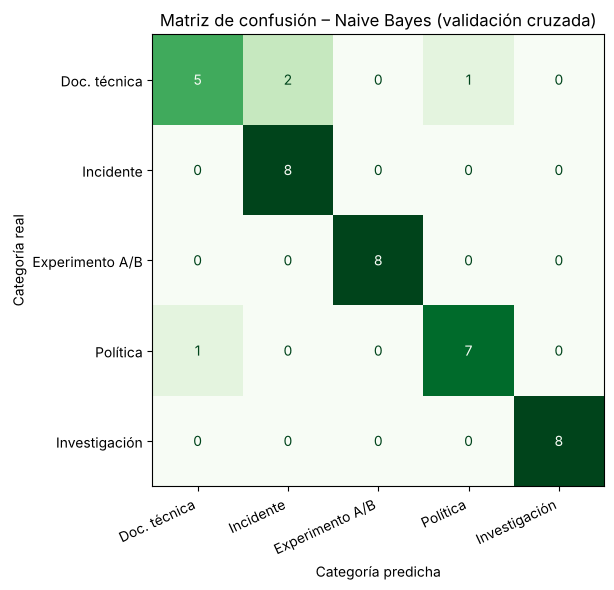

,id,título,categoría real,el modelo dijo
0,DT01,Guía de despliegue del servicio de pagos,Documentación técnica,Reporte de incidente
1,DT05,Manual de monitoreo y alertas de la plataforma,Documentación técnica,Reporte de incidente
2,DT06,Modelo de datos del sistema de recomendaciones,Documentación técnica,Política interna
3,PO03,Lineamientos de uso responsable de inteligencia artificial,Política interna,Documentación técnica


In [15]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

orden = ["documentacion_tecnica", "reporte_incidente", "experimento_ab", "politica_interna", "investigacion_usuarios"]
cortos = ["Doc. técnica", "Incidente", "Experimento A/B", "Política", "Investigación"]

pred_cv = cross_val_predict(Pipeline([("tfidf", crear_vectorizador()), ("modelo", MultinomialNB(alpha=0.1))]),
                            textos, etiquetas, cv=cv)
mc = confusion_matrix(etiquetas, pred_cv, labels=orden)
print(f"Aciertos: {np.trace(mc)} de {mc.sum()} documentos ({np.trace(mc)/mc.sum():.1%})")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(mc, display_labels=cortos).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_xlabel("Categoría predicha"); ax.set_ylabel("Categoría real")
ax.set_title("Matriz de confusión – Naive Bayes (validación cruzada)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

errores = [(df.loc[i, "id"], df.loc[i, "titulo"], NOMBRES[etiquetas[i]], NOMBRES[pred_cv[i]])
           for i in range(len(df)) if pred_cv[i] != etiquetas[i]]
pd.DataFrame(errores, columns=["id", "título", "categoría real", "el modelo dijo"])

## Extra B. Mapa visual del conocimiento
Se reduce cada vector TF-IDF (miles de dimensiones) a solo 2 con **SVD** para poder dibujarlo. Las estrellas son los 6 documentos nuevos, coloreados con la categoría que les asignó el clasificador.

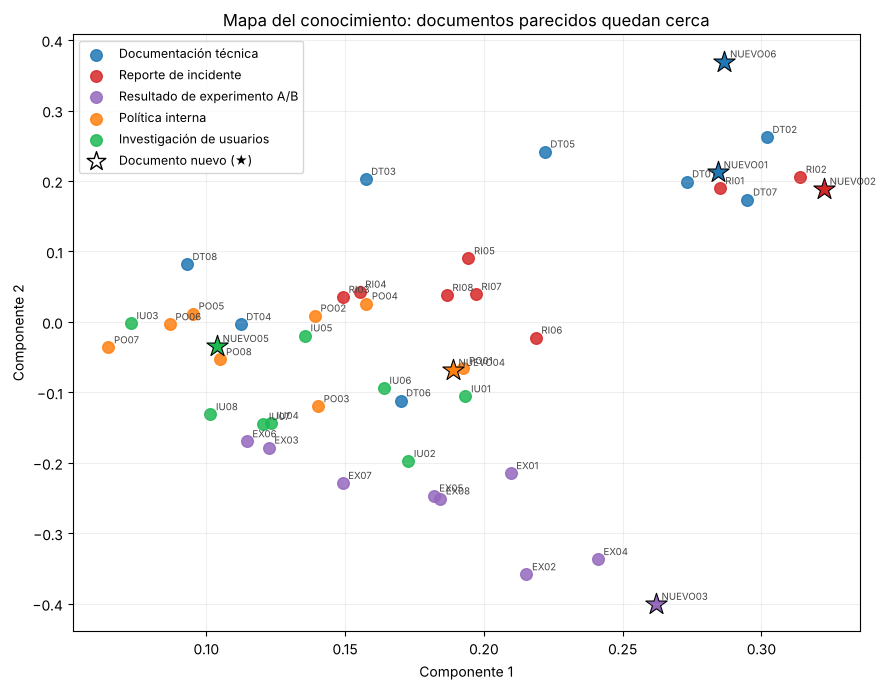

In [16]:
from sklearn.decomposition import TruncatedSVD

coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(matriz_busqueda)
colores = {"documentacion_tecnica": "#1f77b4", "reporte_incidente": "#d62728", "experimento_ab": "#9467bd",
           "politica_interna": "#ff7f0e", "investigacion_usuarios": "#1DB954"}

fig, ax = plt.subplots(figsize=(9, 7))
for cat in orden:
    pts = [i for i, d in enumerate(TODOS) if d["categoria"] == cat and d["id"] not in ids_nuevos]
    ax.scatter(coords[pts, 0], coords[pts, 1], s=70, color=colores[cat], label=NOMBRES[cat], alpha=0.85)
for i, d in enumerate(TODOS):
    if d["id"] in ids_nuevos:
        ax.scatter(coords[i, 0], coords[i, 1], s=260, marker="*", color=colores[d["categoria"]], edgecolor="black", linewidth=0.8)
    ax.annotate(d["id"], (coords[i, 0], coords[i, 1]), fontsize=7, xytext=(4, 3), textcoords="offset points", color="#444444")
ax.scatter([], [], s=200, marker="*", color="white", edgecolor="black", label="Documento nuevo (★)")
ax.set_title("Mapa del conocimiento: documentos parecidos quedan cerca")
ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
ax.legend(loc="best", fontsize=9); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()